In [166]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
%config InlineBackend.figure_format = 'svg'

In [167]:
def leer_csv_tektronix(ruta):
    df = pd.read_csv(ruta, header=None, usecols=[3, 4])
    df.columns = ['tiempo', 'voltaje']
    df = df.dropna()
    df['tiempo'] = df['tiempo'].astype(float)
    df['voltaje'] = df['voltaje'].astype(float)
    return df

def procesar_amplitudes(carpeta, frecuencias):
    resultados = []
    for freq in frecuencias:
        ruta = os.path.join(carpeta, f"{freq}Hz.CSV")
        if os.path.exists(ruta):
            df = leer_csv_tektronix(ruta)
            voltaje = df['voltaje'].values
            v_pp = np.max(voltaje) - np.min(voltaje)
            resultados.append({'Frecuencia (Hz)': freq, 'V_pp (V)': v_pp})
    return pd.DataFrame(resultados)

def calcular_frecuencias_corte(df):
    if df.empty: return None, None, None
    
    # Encontrar el índice del pico máximo
    idx_max = df['Amplitud (dB)'].idxmax()
    
    # Separar en lado izquierdo (subida) y derecho (bajada)
    df_izq = df.iloc[:idx_max+1]
    df_der = df.iloc[idx_max:]
    
    # Interpolar f_L (-3 dB en la subida)
    f_L = np.interp(-3, df_izq['Amplitud (dB)'], df_izq['Frecuencia (Hz)'])
    
    # Interpolar f_H (-3 dB en la bajada, invirtiendo para que los dB sean crecientes)
    f_H = np.interp(-3, df_der['Amplitud (dB)'].iloc[::-1], df_der['Frecuencia (Hz)'].iloc[::-1])
    
    ancho_banda = f_H - f_L
    return f_L, f_H, ancho_banda



def procesar_polares(carpeta, angulos):
    resultados = []
    
    for angulo in angulos:
        nombre = f"{angulo}g.CSV"
        ruta = os.path.join(carpeta, nombre)
        
        if os.path.exists(ruta):
            df = leer_csv_tektronix(ruta)
            voltaje = df['voltaje'].values
            v_pp = np.max(voltaje) - np.min(voltaje)
            
            resultados.append({
                'Ángulo (°)': angulo,
                'V_pp (V)': v_pp
            })
    
    return pd.DataFrame(resultados)

In [168]:
# Frecuencias requeridas
frecuencias = [100, 200, 500, 1000, 2000, 3000, 4000, 6000, 8000, 10000, 12000, 15000]

# Extraer datos
df_sin = procesar_amplitudes('Datos/Sin_Filtro/', frecuencias)
df_con = procesar_amplitudes('Datos/Con_Filtro/', frecuencias)

# Normalizar al máximo global absoluto
v_pp_max_global = max(
    df_sin['V_pp (V)'].max() if not df_sin.empty else 0,
    df_con['V_pp (V)'].max() if not df_con.empty else 0
)

In [169]:
if not df_sin.empty:
    v_pp_max_sin = df_sin['V_pp (V)'].max()
    v_pp_min_sin = df_sin['V_pp (V)'].min()
    
    # Normalización respecto al máximo local
    df_sin['Amplitud (dB)'] = 20 * np.log10(df_sin['V_pp (V)'] / v_pp_max_sin)
    fL_sin, fH_sin, bw_sin = calcular_frecuencias_corte(df_sin)
    
    print(f"--- Sin Filtro ---")
    print(f"V_pp Mínimo: {v_pp_min_sin:.4f} V | V_pp Máximo: {v_pp_max_sin:.4f} V")
    print(f"f_L (-3dB): {fL_sin:.2f} Hz | f_H (-3dB): {fH_sin:.2f} Hz | Ancho de Banda: {bw_sin:.2f} Hz\n")

if not df_con.empty:
    v_pp_max_con = df_con['V_pp (V)'].max()
    v_pp_min_con = df_con['V_pp (V)'].min()
    
    # Normalización respecto al máximo local
    df_con['Amplitud (dB)'] = 20 * np.log10(df_con['V_pp (V)'] / v_pp_max_con)
    fL_con, fH_con, bw_con = calcular_frecuencias_corte(df_con)
    
    print(f"--- Con Filtro ---")
    print(f"V_pp Mínimo: {v_pp_min_con:.4f} V | V_pp Máximo: {v_pp_max_con:.4f} V")
    print(f"f_L (-3dB): {fL_con:.2f} Hz | f_H (-3dB): {fH_con:.2f} Hz | Ancho de Banda: {bw_con:.2f} Hz\n")

--- Sin Filtro ---
V_pp Mínimo: 0.0160 V | V_pp Máximo: 1.0400 V
f_L (-3dB): 2941.94 Hz | f_H (-3dB): 6722.94 Hz | Ancho de Banda: 3780.99 Hz

--- Con Filtro ---
V_pp Mínimo: 0.1520 V | V_pp Máximo: 10.2400 V
f_L (-3dB): 2667.58 Hz | f_H (-3dB): 6454.51 Hz | Ancho de Banda: 3786.93 Hz



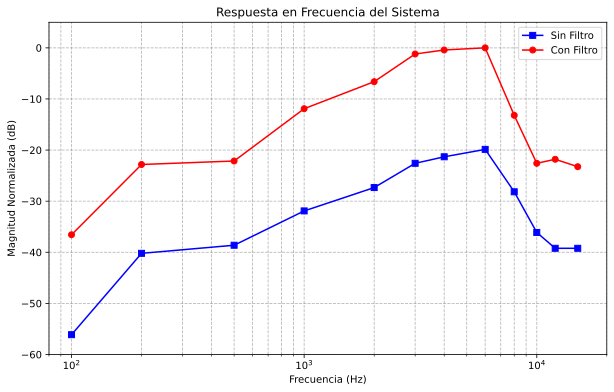

In [178]:

if not df_sin.empty:
    df_sin['Amplitud Global (dB)'] = 20 * np.log10(df_sin['V_pp (V)'] / v_pp_max_global)

if not df_con.empty:
    df_con['Amplitud Global (dB)'] = 20 * np.log10(df_con['V_pp (V)'] / v_pp_max_global)

plt.figure(figsize=(10, 6))

# Línea de referencia a -3 dB
#plt.axhline(y=-3, color='gray', linestyle='--', label='Referencia -3 dB')

if not df_sin.empty:
    plt.semilogx(df_sin['Frecuencia (Hz)'], df_sin['Amplitud Global (dB)'], marker='s', color='b', label='Sin Filtro')
    #plt.plot([fL_sin, fH_sin], [-3, -3], 'bo', markersize=8) # Puntos de corte

if not df_con.empty:
    plt.semilogx(df_con['Frecuencia (Hz)'], df_con['Amplitud Global (dB)'], marker='o', color='r', label='Con Filtro')
    #plt.plot([fL_con, fH_con], [-3, -3], 'ro', markersize=8) # Puntos de corte

plt.title('Respuesta en Frecuencia del Sistema')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Magnitud Normalizada (dB)')
plt.grid(True, which="both", ls="--", color='gray', alpha=0.6)
plt.legend()
plt.xlim(80, 20000)
plt.ylim(-60, 5)

plt.show()

In [171]:
# Mostrar tablas de resultados
if not df_sin.empty:
    print("--- Tabla de Resultados: Micrófono Sin Filtro ---")
    print(df_sin.to_markdown(index=False))
    print("\n")

if not df_con.empty:
    print("--- Tabla de Resultados: Sistema Con Filtro ---")
    print(df_con.to_markdown(index=False))

--- Tabla de Resultados: Micrófono Sin Filtro ---
|   Frecuencia (Hz) |   V_pp (V) |   Amplitud (dB) |   Amplitud Global (dB) |
|------------------:|-----------:|----------------:|-----------------------:|
|               100 |      0.016 |       -36.2583  |               -56.1236 |
|               200 |      0.1   |       -20.3407  |               -40.206  |
|               500 |      0.12  |       -18.757   |               -38.6224 |
|              1000 |      0.26  |       -12.0412  |               -31.9065 |
|              2000 |      0.44  |        -7.47161 |               -27.3369 |
|              3000 |      0.76  |        -2.72439 |               -22.5897 |
|              4000 |      0.88  |        -1.45101 |               -21.3163 |
|              6000 |      1.04  |         0       |               -19.8653 |
|              8000 |      0.4   |        -8.29947 |               -28.1648 |
|             10000 |      0.16  |       -16.2583  |               -36.1236 |
|             

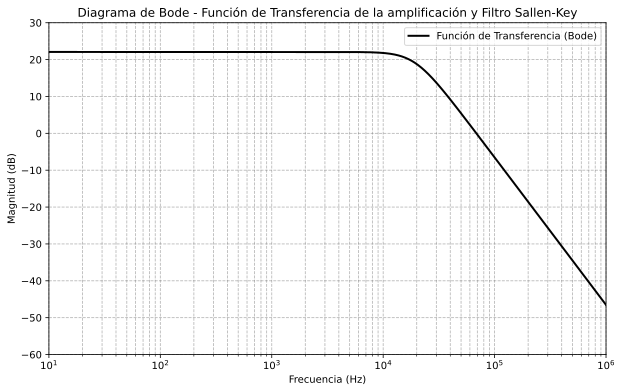

In [172]:
# --- Cálculo de la Función de Transferencia Teórica (Sin Normalizar, hasta 1 MHz) ---
R1, R2 = 2200, 2200
C1, C2 = 4.7e-9, 3e-9
Rf1, Rg1 = 1000, 100
Rf2, Rg2 = 5100, 33000

# Ganancias lineales
A = 1 + (Rf1 / Rg1) # Amplificador No Inversor
K = 1 + (Rf2 / Rg2) # Etapa Sallen-Key
w_c = 1 / np.sqrt(R1 * R2 * C1 * C2)
Q = np.sqrt(R1 * R2 * C1 * C2) / (C2 * (R1 + R2) + R1 * C1 * (1 - K))

# Vector para graficar el Bode teórico desde 10 Hz (10^1) hasta 1 MHz (10^6)
f_teo = np.logspace(1, 6, 1000)
w_teo = 2 * np.pi * f_teo

# Magnitud lineal de la cascada completa y conversión a dB reales (sin normalizar)
mag_filtro_lineal = (A * K * w_c**2) / np.sqrt((w_c**2 - w_teo**2)**2 + ((w_c * w_teo) / Q)**2)
mag_filtro_dB_real = 20 * np.log10(mag_filtro_lineal)

# --- Gráfica 1: Bode del Filtro Teórico (Ganancia Real) ---
plt.figure(figsize=(10, 6))
plt.semilogx(f_teo, mag_filtro_dB_real, 'k-', linewidth=2, label='Función de Transferencia (Bode)')
plt.title('Diagrama de Bode - Función de Transferencia de la amplificación y Filtro Sallen-Key')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Magnitud (dB)')
plt.grid(True, which="both", ls="--", color='gray', alpha=0.6)
plt.legend()

# Ajuste de límites para visualizar el espectro completo
plt.xlim(10, 1000000)
plt.ylim(-60, 30) # Ampliado hacia abajo para capturar la caída de -40 dB/década

plt.show()

# --- Cálculo de la Suma Teórica sobre Datos Físicos (Se mantiene normalizado para comparar) ---
if not df_sin.empty and not df_con.empty:
    w_discreto = 2 * np.pi * np.array(frecuencias)
    
    # Ganancia lineal total (Amplificador + Filtro) en las frecuencias medidas
    ganancia_discreta_lineal = (A * K * w_c**2) / np.sqrt((w_c**2 - w_discreto**2)**2 + ((w_c * w_discreto) / Q)**2)
    
    # V_pp teórico: Entrada cruda (micrófono) * Ganancia total teórica
    v_pp_teorico = df_sin['V_pp (V)'].values * ganancia_discreta_lineal
    
    # Normalizar respecto al valor MÁXIMO del sistema completo físico para la gráfica comparativa
    v_pp_max_con_fisico = df_con['V_pp (V)'].max()
    v_pp_teorico_norm = v_pp_teorico / v_pp_max_con_fisico
    
    # Convertir a dB el resultado final de la cascada
    suma_teorica_dB = 20 * np.log10(v_pp_teorico_norm)

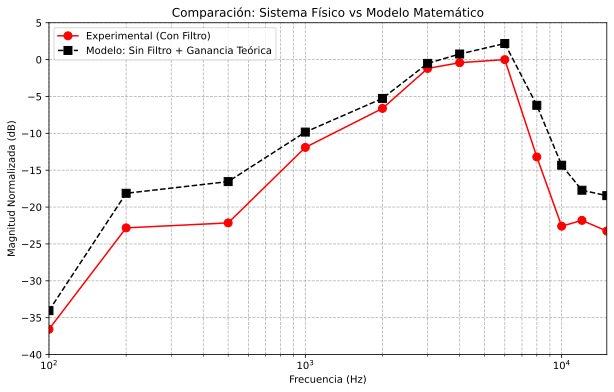

In [173]:


# --- Gráfica 2: Con Filtro vs Modelo Teórico ---
if not df_sin.empty and not df_con.empty:
    plt.figure(figsize=(10, 6))
    
    # Medición Experimental con Filtro
    plt.semilogx(df_con['Frecuencia (Hz)'], df_con['Amplitud (dB)'], 
                 marker='o', linestyle='-', color='r', markersize=8, 
                 label='Experimental (Con Filtro)')
                 
    # Resultado del modelo matemático ajustado
    plt.semilogx(frecuencias, suma_teorica_dB, 
                 marker='s', linestyle='--', color='k', markersize=8, 
                 label='Modelo: Sin Filtro + Ganancia Teórica')

    plt.title('Comparación: Sistema Físico vs Modelo Matemático')
    plt.xlabel('Frecuencia (Hz)')
    plt.ylabel('Magnitud Normalizada (dB)')
    plt.grid(True, which="both", ls="--", color='gray', alpha=0.6)
    plt.legend()
    plt.xlim(100, 15000)
    plt.ylim(-40, 5)
    
    plt.show()

In [174]:
# --- Módulo para el Cálculo de Error Relativo ---
if not df_sin.empty and not df_con.empty:
    # Se utilizan las variables 'v_pp_teorico' y 'suma_teorica_dB' calculadas en el bloque anterior
    
    tabla_errores = pd.DataFrame({
        'Frecuencia (Hz)': df_con['Frecuencia (Hz)'],
        'V_pp Teórico (V)': v_pp_teorico,
        'V_pp Medido (V)': df_con['V_pp (V)'].values,
        'Error Relativo (%)': np.abs((df_con['V_pp (V)'].values - v_pp_teorico) / v_pp_teorico) * 100,
        'Diferencia (dB)': np.abs(df_con['Amplitud Global (dB)'].values - suma_teorica_dB)
    })
    
    # Redondeo para que la tabla sea fácil de leer en el reporte
    tabla_errores['V_pp Teórico (V)'] = tabla_errores['V_pp Teórico (V)'].round(4)
    tabla_errores['V_pp Medido (V)'] = tabla_errores['V_pp Medido (V)'].round(4)
    tabla_errores['Error Relativo (%)'] = tabla_errores['Error Relativo (%)'].round(2)
    tabla_errores['Diferencia (dB)'] = tabla_errores['Diferencia (dB)'].round(2)
    
    print("--- Tabla Comparativa: Modelo Matemático vs Sistema Físico ---")
    print(tabla_errores.to_markdown(index=False))


--- Tabla Comparativa: Modelo Matemático vs Sistema Físico ---
|   Frecuencia (Hz) |   V_pp Teórico (V) |   V_pp Medido (V) |   Error Relativo (%) |   Diferencia (dB) |
|------------------:|-------------------:|------------------:|---------------------:|------------------:|
|               100 |             0.2032 |             0.152 |                25.2  |              2.52 |
|               200 |             1.27   |             0.74  |                41.73 |              4.69 |
|               500 |             1.524  |             0.8   |                47.51 |              5.6  |
|              1000 |             3.3021 |             2.6   |                21.26 |              2.08 |
|              2000 |             5.5885 |             4.78  |                14.47 |              1.36 |
|              3000 |             9.6524 |             8.92  |                 7.59 |              0.69 |
|              4000 |            11.1723 |             9.76  |                12.64 |    

In [175]:
angulos = [0, 30, 60, 90, 120, 150, 180]

# Extraer datos de los archivos
df_polar_sin = procesar_polares('Datos/Sin_Filtro/Polares/', angulos)
df_polar_con = procesar_polares('Datos/Con_Filtro/Polares/', angulos)

# Aplicar normalización individual y cálculo de dB a cada DataFrame
for df in [df_polar_sin, df_polar_con]:
    if not df.empty:
        # Normalización individual (cada conjunto escala a su propio máximo)
        df['V_pp_norm'] = df['V_pp (V)'] / df['V_pp (V)'].max()
        
        # Conversión a dB (evitando logaritmos de cero)
        df['Respuesta (dB)'] = 20 * np.log10(np.maximum(df['V_pp_norm'], 1e-6))

In [176]:
# Tabla Sin Filtro
print("=" * 60)
print("         TABLA DE DIRECTIVIDAD: SIN FILTRO         ")
print("=" * 60)
if not df_polar_sin.empty:
    print(df_polar_sin.to_string(index=False, float_format=lambda x: f"{x:.3f}"))
else:
    print("No hay datos disponibles.")

# Tabla Con Filtro
print("\n" + "=" * 60)
print("         TABLA DE DIRECTIVIDAD: CON FILTRO         ")
print("=" * 60)
if not df_polar_con.empty:
    print(df_polar_con.to_string(index=False, float_format=lambda x: f"{x:.3f}"))
else:
    print("No hay datos disponibles.")

         TABLA DE DIRECTIVIDAD: SIN FILTRO         
 Ángulo (°)  V_pp (V)  V_pp_norm  Respuesta (dB)
          0     0.100      0.333          -9.542
         30     0.100      0.333          -9.542
         60     0.140      0.467          -6.620
         90     0.300      1.000           0.000
        120     0.160      0.533          -5.460
        150     0.140      0.467          -6.620
        180     0.160      0.533          -5.460

         TABLA DE DIRECTIVIDAD: CON FILTRO         
 Ángulo (°)  V_pp (V)  V_pp_norm  Respuesta (dB)
          0     0.580      0.186         -14.615
         30     0.640      0.205         -13.759
         60     1.380      0.442          -7.086
         90     3.120      1.000           0.000
        120     1.460      0.468          -6.596
        150     1.060      0.340          -9.377
        180     1.440      0.462          -6.716


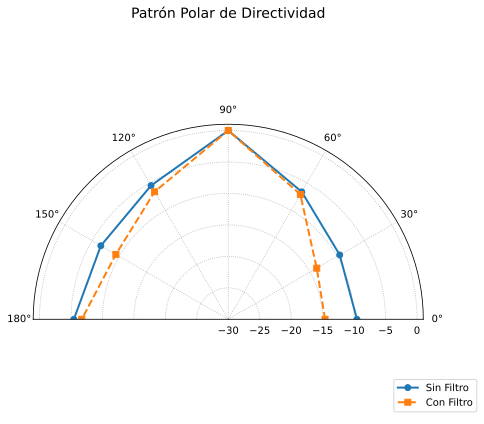

In [177]:
# Convertir ángulos a radianes
angulos_rad = np.deg2rad(angulos)

plt.figure(figsize=(8, 6))
ax = plt.subplot(111, projection='polar')

# Curva Sin Filtro
if not df_polar_sin.empty:
    ax.plot(angulos_rad, df_polar_sin['Respuesta (dB)'], marker='o', linestyle='-', 
            linewidth=2, label='Sin Filtro', color='#1f77b4')

# Curva Con Filtro
if not df_polar_con.empty:
    ax.plot(angulos_rad, df_polar_con['Respuesta (dB)'], marker='s', linestyle='--', 
            linewidth=2, label='Con Filtro', color='#ff7f0e')

# Rango angular: Semicírculo superior (0° a 180°)
ax.set_thetamin(0)
ax.set_thetamax(180)

# Rango radial: 0 dB en la superficie exterior, -30 dB hacia el centro
ax.set_rlim(-30, 1)

# Formato visual
ax.set_title("Patrón Polar de Directividad", va='bottom', fontsize=14)
ax.set_rlabel_position(45)
ax.grid(True, linestyle=':')

plt.legend(loc='lower right', bbox_to_anchor=(1.15, 0))
plt.tight_layout()
plt.show()